## Identify the optimal XIC for a precursor

By default, for each precursor, three MS1-level XICs (monoisotopic and two isotopic) and six MS2-level XICs (product ions) are extracted. Among these, one XIC is selected as the optimal trace based on its correlation with the other XICs, weighted by its shape consistency with a Gaussian curve and its intensity. This optimal XIC is then used as the reference to remove potential interference from the other XICs.

After the JUMPdiaq analysis is finished, the extracted XIC data for each run is stored in the `xic_files` folder in the output directory.

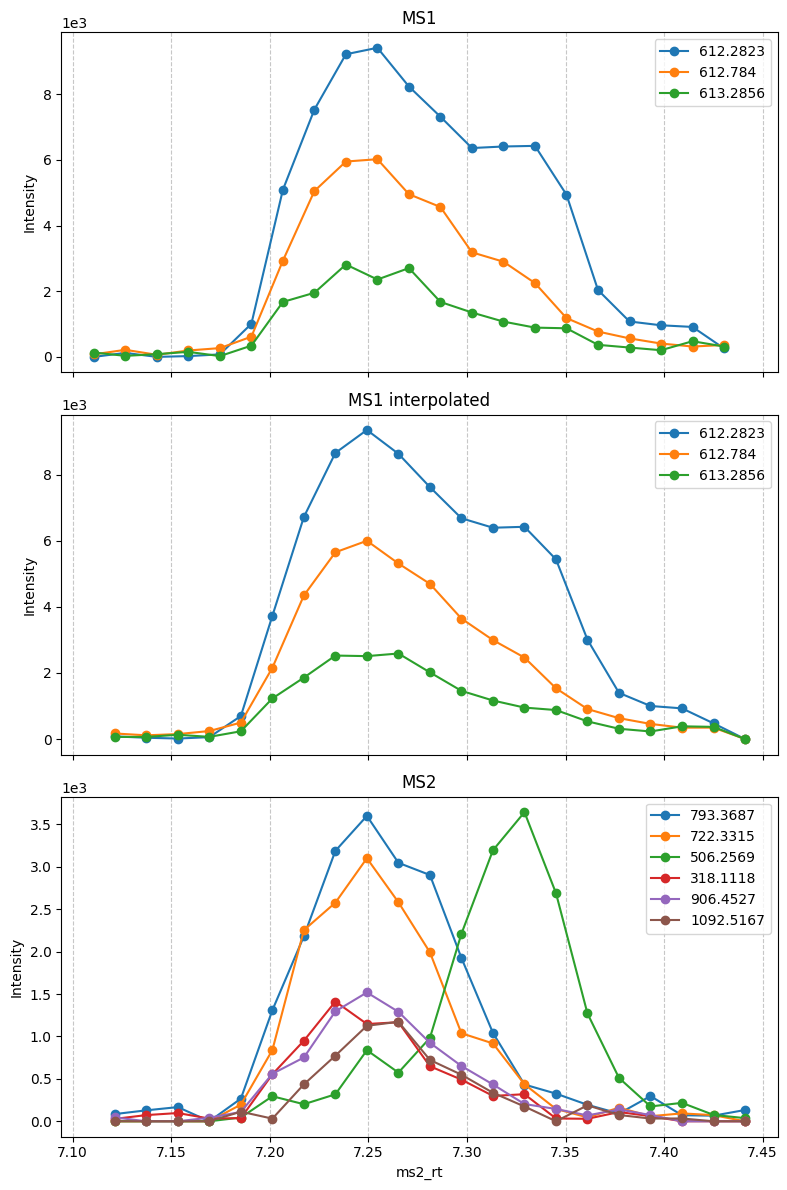

In [9]:
from jumpdiaq.elution_peaks import extract_ms1_ms2_from_xic_file
import matplotlib.pyplot as plt

# extract XIC data for a precursor
precursor_id = "MGELASESQGSK2"
xic_file = "../tests/H7_3_S1-E5_1_667.xic.parquet"
ms1_df, ms2_df, ms1_i_df = extract_ms1_ms2_from_xic_file(xic_file, precursor_id)

# Draw plots to show XICs
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 12), sharex=True)
# MS1 XICs plot
ms1_df.plot(x='ms1_rt', kind='line', marker='o', ax=ax1, ylabel='Intensity')
ax1.ticklabel_format(style='sci', axis='y', scilimits=(0, 3), useOffset=True)
ax1.set_title("MS1")
ax1.grid(axis='x', linestyle='--', alpha=0.7)
# Interpolated MS1 XICs plot
ms1_i_df.plot(x='ms2_rt', kind='line', marker='o', ax=ax2, ylabel='Intensity')
ax2.ticklabel_format(style='sci', axis='y', scilimits=(0, 3), useOffset=True)
ax2.set_title("MS1 interpolated")
ax2.grid(axis='x', linestyle='--', alpha=0.7)
# MS2 XICs plot
ms2_df.plot(x='ms2_rt', kind='line', marker='o', ax=ax3, ylabel='Intensity')
ax3.ticklabel_format(style='sci', axis='y', scilimits=(0, 3), useOffset=True)
ax3.set_title("MS2")
ax3.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In the above example, we can see that there are interferences at the MS1-level XICs and one of the MS2-level XICs. So we will find the optimal XIC at the MS2-level.

#### Define the XIC region to evaluate

In [10]:
ms1 = ms1_df.drop(columns=['ms1_rt']).values
ms1_i = ms1_i_df.drop(columns=['ms2_rt']).values
ms2 = ms2_df.drop(columns=['ms2_rt']).values

apex = ms1.shape[0] // 2
radius = 5
region = slice(max(0, apex - radius), 
               min(ms1.shape[0] - 2, apex + radius + 1))

optimal_xic_source = 'ms2'
if optimal_xic_source == 'ms1':
    xics = ms1.copy()
    n_ms1 = ms1.shape[1]
    n_ms2 = 0
elif optimal_xic_source == 'ms2':
    xics = ms2.copy()
    n_ms1 = 0
    n_ms2 = ms2.shape[1]
elif optimal_xic_source == 'ms1_ms2':
    xics = np.concatenate((ms1, ms2), axis = 1)
    n_ms1 = ms1.shape[1]
    n_ms2 = ms2.shape[1]

xics_region = xics[region, :]

#### Calculate the XIC correlation score

In [11]:
import numpy as np
from jumpdiaq.elution_peaks import get_corr_matrix

corr_method = 0
# Get correlation matrix between ions
corr_matrix = get_corr_matrix(xics_region, corr_method)
corr_matrix[corr_matrix < 0] = 1e-6
# 
corr_scores = np.sum(corr_matrix, axis=1)
# 
max_corr = np.max(corr_scores)
corr_scores = corr_scores / max_corr if max_corr > 0 else corr_scores
print(corr_scores)

[9.90633679e-01 9.91875213e-01 1.31486876e-06 9.47871457e-01
 1.00000000e+00 9.24179381e-01]


#### Calculate the XIC intensity score

In [12]:
# Intensity (area under curve) per ion
intensities = np.sum(xics_region, axis=0)
# Norm ms1 intensity
if n_ms1 > 0 and n_ms2 > 0:
    ms1_intensities = intensities[0:n_ms1]
    ms2_intensities = intensities[n_ms1:]
    
    mono_ms1 = ms1_intensities[0]
    max_ms2 = np.max(ms2_intensities)
    if mono_ms1 > 0 and max_ms2 > 0 and mono_ms1 > max_ms2:
        ms1_intensities = ms1_intensities / (mono_ms1 / max_ms2)
        
    intensities = np.concatenate((ms1_intensities, ms2_intensities), axis=0)

# get relative ratio of intensity
log2_intensities = np.log2(intensities + 1)
max_log2_intensity = np.max(log2_intensities)
if max_log2_intensity > 0:
    intensity_scores = log2_intensities / max_log2_intensity
else:
    intensity_scores = np.ones(xics_region.shape[1])

print(intensity_scores)

[1.         0.97627853 0.97809844 0.89404061 0.90481826 0.86914502]


#### Calculate the XIC shape score

In [42]:
from jumpdiaq.elution_peaks import gaussian_curve, corr, smooth, get_fwhm

def calculate_shape_score(xic, corr_method):
    xic_fwhm = max(1, get_fwhm(xic))
    apex = np.argmax(xic)
    
    # Bell curve
    bell = gaussian_curve(len(xic), apex, xic_fwhm, np.max(xic))
    bell_corr = corr(xic, bell, corr_method)
    
    # Tail Ratio
    area_left = 0.0
    for i in range(apex+1):
        area_left += xic[i]
    area_left = max(1e-6, area_left)
    
    area_right = 0.0
    for i in range(apex, len(xic)):
        area_right += xic[i]
    area_right = max(1e-6, area_right)
    
    tail_balance = min(area_left, area_right) / max(area_left, area_right)
    
    # Combined shape score
    shape_score = bell_corr * tail_balance
    
    return shape_score

# shape score
shape_scores = np.zeros(xics_region.shape[1])
for i in range(xics_region.shape[1]):
    xic = xics_region[:, i]
    xic_smooth = smooth(xic)
    shape_scores[i] = calculate_shape_score(xic_smooth, corr_method)
print(f"Raw shape score: {shape_scores}")

# Normalized shape score
max_score = max(shape_scores)
shape_scores = shape_scores / max_score if max_score > 0 else shape_scores
shape_scores[shape_scores < 0] = 1e-6
print(f"Normalized shape score: {shape_scores}")

Raw shape score: [0.75797419 0.86075346 0.6251587  0.5123265  0.78255895 0.53086135]
Normalized shape score: [0.88059382 1.         0.7262924  0.59520701 0.90915574 0.61674031]


In [39]:
# check one example
xic = smooth(xics_region[:, 1])

xic_fwhm = max(1, get_fwhm(xic))
apex = np.argmax(xic)

# Bell curve
bell = gaussian_curve(len(xic), apex, xic_fwhm, np.max(xic))
bell_corr = corr(xic, bell, corr_method)
print(f"Correlation with the Gaussian curve: {bell_corr}")

Correlation with the Gaussian curve: 0.9958445646338571


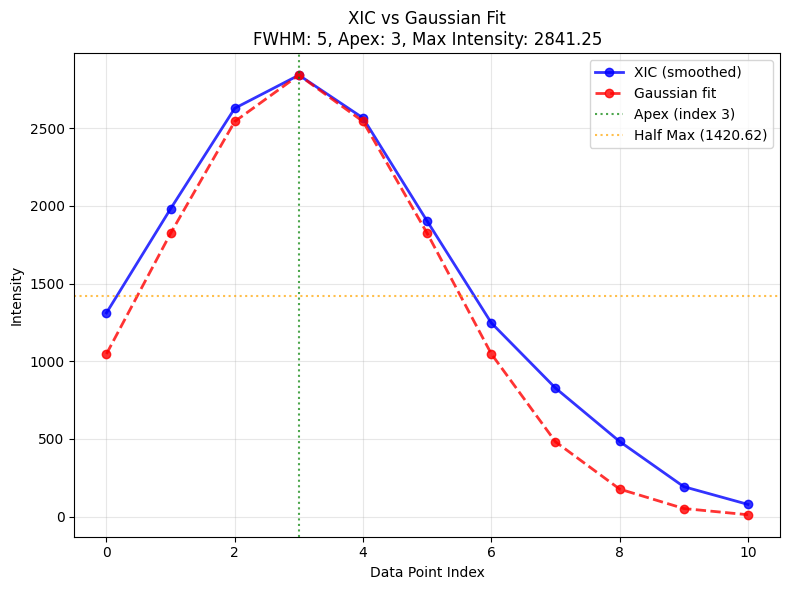

In [40]:
# Create the plot
plt.figure(figsize=(8, 6))
plt.plot(range(len(xic)), xic, 'b-', marker='o', linewidth=2, label='XIC (smoothed)', alpha=0.8)
plt.plot(range(len(bell)), bell, 'r--', marker='o', linewidth=2, label='Gaussian fit', alpha=0.8)
plt.axvline(x=apex, color='green', linestyle=':', alpha=0.7, label=f'Apex (index {apex})')
# Mark the half-maximum level
half_max = np.max(xic) / 2.0
plt.axhline(y=half_max, color='orange', linestyle=':', alpha=0.7, label=f'Half Max ({half_max:.2f})')

# Formatting
plt.xlabel('Data Point Index')
plt.ylabel('Intensity')
plt.title(f'XIC vs Gaussian Fit\nFWHM: {xic_fwhm}, Apex: {apex}, Max Intensity: {np.max(xic):.2f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

In [41]:
# Tail Ratio
area_left = 0.0
for i in range(apex+1):
    area_left += xic[i]
area_left = max(1e-6, area_left)

area_right = 0.0
for i in range(apex, len(xic)):
    area_right += xic[i]
area_right = max(1e-6, area_right)

tail_balance = min(area_left, area_right) / max(area_left, area_right)
print(f"Tail balance score: {tail_balance}")

# Combined shape score
shape_score = bell_corr * tail_balance
print(f"Final shape score: {shape_score}")

Tail balance score: 0.864345195524756
Final shape score: 0.8607534649307167


#### Calculate the combined score

In [23]:
# Method 1: Multiplication, all criteria matter equally and severely penalize low performance in any one of them
scores = corr_scores * intensity_scores * shape_scores 
print(scores)

[8.72345900e-01 9.68346476e-01 9.34063657e-07 5.04399601e-01
 8.22620713e-01 4.95394125e-01]


In [24]:
# Method 2: Weighted sum, allowing strong scores in one area to offset weaker scores in others
scores = (0.5*corr_scores) + (0.3*intensity_scores) + (0.2*shape_scores) 
print(scores)

[0.9714356  0.98882117 0.43868867 0.86118932 0.95327663 0.84618126]


#### Identify the optimal XIC

In [25]:
min_shape_score=0.3
min_apex_intensity=10
min_apex_evidence=0.99

indices = np.argsort(scores)[::-1]
for idx in indices:
    ion_xic = xics[region, idx]
    elution = smooth(ion_xic)
    elution_apex = np.argmax(elution)
        
    refined_apex = region.start + elution_apex
    new_region = slice(max(0, refined_apex - radius), min(ms2.shape[0], refined_apex + radius + 1))
    elution = smooth(xics[new_region, idx])
    elution_apex = np.argmax(elution)
    elution_apex_global = new_region.start + elution_apex
    fwhm = max(1, get_fwhm(elution))
    
    # shape score
    shape_score = calculate_shape_score(elution, corr_method)
    if shape_score < min_shape_score:
        continue
    
    apex_intensity = elution[elution_apex]
    if apex_intensity < min_apex_intensity:
        continue

    # Check for peak shoulder: no nearby points should be much higher
    window_length = new_region.stop - new_region.start
    flank_start = max(elution_apex - elution_apex // 3, 1)
    flank_end = min(elution_apex + elution_apex // 3 + 1, window_length)
    flank = elution[flank_start:flank_end]
    if np.any(flank > apex_intensity * 1.5):
        continue

    # Check wider evidence: apex should be distinct
    left = elution[:elution_apex-1] if elution_apex > 1 else np.array([])
    right = elution[elution_apex+2:] if elution_apex+2 < len(elution) else np.array([])
    max_neighbor = np.max(np.concatenate([left, right])) if left.size + right.size > 0 else 0
    if apex_intensity < max_neighbor * min_apex_evidence:
        continue

    # All checks passed
    found = True
    break

found

True

In [26]:
if not found:
    optimal_xic = -1
    optimal_xic_type = 0
    elution_apex_global = apex
    fwhm = radius
else:
    optimal_xic = idx
    if optimal_xic_source == 'ms1':
        optimal_xic_type = 1
    elif optimal_xic_source == 'ms2':
        optimal_xic_type = 2
    elif optimal_xic_source == 'ms1_ms2':
        if optimal_xic >= n_ms1:
            optimal_xic_type = 2
            optimal_xic = optimal_xic - n_ms1
        else:
            optimal_xic_type = 1
print(f"MS-level of the optimal XIC: MS{optimal_xic_type}")
print(f"Optimal XIC index: {optimal_xic}") 
print(f"XIC apex index: {elution_apex_global}")
print(f"FWHM: {fwhm}")

MS-level of the optimal XIC: MS2
Optimal XIC index: 1
XIC apex index: 8
FWHM: 5


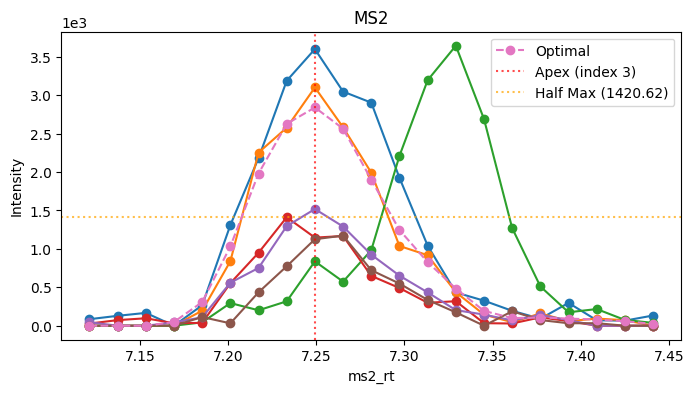

In [38]:
ax = ms2_df.plot(x='ms2_rt', kind='line', marker='o', ylabel='Intensity', figsize=(8,4))
for line in ax.get_lines():
    line.set_label('_nolegend_')

elution = smooth(ms2[:, optimal_xic])
ax.plot(ms2_df['ms2_rt'], elution, marker='o', linestyle='--', label='Optimal')
ax.axvline(x=ms2_df['ms2_rt'][elution_apex_global], color='red', linestyle=':', alpha=0.7, label=f'Apex (index {apex})')
half_max = np.max(elution) / 2.0
ax.axhline(y=half_max, color='orange', linestyle=':', alpha=0.7, label=f'Half Max ({half_max:.2f})')
ax.ticklabel_format(style='sci', axis='y', scilimits=(0, 3), useOffset=True)
ax.set_title("MS2")
ax.legend()

### Summary
The above analysis can be done with a single function:

In [30]:
from jumpdiaq.elution_peaks import identify_optimal_xic

# find optimal xic
(corr_scores, 
 shape_scores, 
 intensity_scores, 
 scores, 
 optimal_xic, 
 optimal_xic_type, 
 elution_apex, fwhm) = identify_optimal_xic(
                                 ms1_i, 
                                 ms2, 
                                 apex=ms1.shape[0] // 2, 
                                 radius=5, 
                                 corr_method=0, 
                                 shape_weighted=1,
                                 intensity_weighted=1,
                                 optimal_xic_source='ms2',
                                 min_shape_score=0.3,
                                 min_apex_intensity=10,
                                 min_apex_evidence=0.99)

In [31]:
print(f"MS-level of the optimal XIC: MS{optimal_xic_type}")
print(f"Optimal XIC index: {optimal_xic}") 
print(f"XIC apex index: {elution_apex_global}")
print(f"FWHM: {fwhm}")

MS-level of the optimal XIC: MS2
Optimal XIC index: 1
XIC apex index: 8
FWHM: 5
